Skin Disease Classification Using CNN

Project Overview

This project uses Deep Learning and Convolutional Neural Networks (CNN) to classify skin disease images into four categories.

Categories

- Chickenpox
- Measles
- Monkeypox
- Normal

Technologies Used

- Python
- NumPy
- Pandas
- Matplotlib
- Scikit-learn
- Keras
- CNN

Project Workflow

1. Image loading
2. Image resizing and preprocessing
3. Train-test splitting
4. CNN model development
5. Model training
6. Model evaluation
7. New image prediction

Model Architecture

- Convolutional Layer (32 filters)
- Max Pooling
- Convolutional Layer (64 filters)
- Max Pooling
- Flatten
- Dense Layer
- Softmax Output Layer

Model Performance

Test Accuracy: 87%

Note

This is an educational image-classification project and is not intended for clinical diagnosis.


In [66]:
from skimage.io import imread
from skimage.transform import resize
import os

In [67]:
x=[]
y=[]
path='/content/drive/MyDrive/Skin Disease'
categories=os.listdir(path)
print(categories)
for category in categories:
  cat_path=os.path.join(path,category)
  print(cat_path)
  images=os.listdir(cat_path)
  for image in images:
    img_path=os.path.join(cat_path,image)
    print(img_path)
    img_array=imread(img_path)
    img_resized=resize(img_array,(150,150,3))
    x.append(img_resized)
    y.append(categories.index(category))



['Monkeypox', 'Normal', 'Chickenpox', 'Measles']
/content/drive/MyDrive/Skin Disease/Monkeypox
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_10.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_100.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_101.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_102.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_103.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_104.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_105.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_106.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_107.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_108.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_109.jpg
/content/drive/MyDrive/Skin Disease/Monkeypox/ds1_MonkeyPox_11.jpg
/content/drive/MyDrive/Skin

In [68]:
import numpy as np
x=np.array(x)
y=np.array(y)

In [69]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42,stratify=y)

In [70]:
len(x_train),len(y_train)

(1143, 1143)

In [71]:
len(x_test),len(y_test)

(286, 286)

In [72]:
x_train.shape,y_train.shape

((1143, 150, 150, 3), (1143,))

In [73]:
x_test.shape,y_test.shape

((286, 150, 150, 3), (286,))

In [74]:
from keras.models import Sequential
from keras.layers import Input,Conv2D,MaxPooling2D,Dense,Flatten

In [75]:
model=Sequential()
model.add(Input(shape=(150,150,3)))
model.add(Conv2D(32,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Flatten())
model.add(Dense(10,activation='relu'))
model.add(Dense(4,activation='softmax'))

In [76]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [77]:
model.fit(x_train,y_train,batch_size=15,epochs=20)

Epoch 1/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.5206 - loss: 1.1704
Epoch 2/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6273 - loss: 0.9124
Epoch 3/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6912 - loss: 0.7586
Epoch 4/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7332 - loss: 0.6250
Epoch 5/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7533 - loss: 0.5871
Epoch 6/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8145 - loss: 0.4904
Epoch 7/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8661 - loss: 0.4097
Epoch 8/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8985 - loss: 0.3470
Epoch 9/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9274 - loss: 0.2742
Epoch 10/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9379 - loss: 0.2332
Epoch 11/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9510 - loss: 0.1841
Epoch 12/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy:

In [78]:
y_pred=model.predict(x_test)
y_pred

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step


array([[1.0000000e+00, 2.5347940e-12, 2.9755365e-21, 4.2773301e-34],
       [2.3408278e-04, 2.2524244e-03, 3.7994988e-03, 9.9371403e-01],
       [1.0000000e+00, 1.0159763e-15, 2.0127564e-22, 1.6935238e-19],
       ...,
       [9.9999881e-01, 1.0827371e-06, 6.4857062e-08, 3.9714648e-13],
       [9.9999976e-01, 2.0487579e-07, 2.9423703e-08, 5.7884068e-19],
       [9.5868725e-01, 4.1312780e-02, 8.8171950e-09, 8.5508901e-28]],
      dtype=float32)

In [79]:
ind=y_pred.argmax(axis=1)
ind

array([0, 3, 0, 1, 0, 0, 2, 1, 0, 0, 0, 0, 2, 2, 0, 1, 0, 2, 3, 2, 0, 3,
       0, 0, 0, 1, 3, 3, 3, 1, 2, 0, 0, 1, 2, 2, 0, 1, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 1, 1, 2, 2, 3, 0, 0, 0, 1, 1, 3, 1, 2, 1, 0, 1, 0, 0, 2,
       3, 1, 1, 0, 1, 0, 0, 1, 0, 0, 3, 0, 0, 0, 1, 3, 1, 0, 0, 0, 0, 2,
       3, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 2, 3, 1, 0, 3, 2, 2, 0, 1, 3, 1,
       1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 2, 0, 0, 1, 3, 0, 1, 0, 3, 0, 0, 2,
       1, 3, 0, 0, 1, 1, 1, 0, 3, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 3, 1, 1,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 2, 0, 1, 2, 1, 3,
       0, 1, 2, 1, 2, 3, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 2, 3, 1,
       0, 1, 0, 3, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 2, 1, 0, 3, 2, 3,
       0, 1, 0, 2, 1, 3, 2, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 2, 2, 0, 1, 2,
       0, 0, 1, 1, 1, 1, 0, 0, 1, 2, 0, 2, 0, 3, 3, 0, 1, 1, 1, 1, 2, 1,
       3, 1, 1, 0, 0, 2, 0, 1, 0, 3, 1, 1, 1, 3, 3, 3, 1, 2, 1, 0, 0, 0])

In [80]:
model.evaluate(x_test,y_test)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.8671 - loss: 0.9714


[0.9713538289070129, 0.867132842540741]

In [81]:
from sklearn.metrics import classification_report
print(classification_report(y_test,ind))

              precision    recall  f1-score   support

           0       0.84      0.93      0.88       109
           1       0.90      0.85      0.87       102
           2       0.97      0.83      0.89        41
           3       0.76      0.76      0.76        34

    accuracy                           0.87       286
   macro avg       0.87      0.84      0.85       286
weighted avg       0.87      0.87      0.87       286



array([[[180, 120,  84],
        [187, 127,  91],
        [196, 136, 100],
        ...,
        [250, 245, 239],
        [249, 244, 238],
        [249, 244, 238]],

       [[179, 119,  83],
        [187, 127,  91],
        [196, 136, 100],
        ...,
        [250, 245, 239],
        [249, 244, 238],
        [249, 244, 238]],

       [[180, 120,  84],
        [188, 128,  92],
        [196, 136, 100],
        ...,
        [250, 245, 239],
        [249, 244, 238],
        [249, 244, 238]],

       ...,

       [[252, 239, 223],
        [252, 239, 223],
        [252, 239, 223],
        ...,
        [253, 250, 243],
        [253, 250, 243],
        [253, 250, 243]],

       [[255, 249, 233],
        [255, 249, 233],
        [255, 249, 233],
        ...,
        [254, 253, 248],
        [254, 253, 248],
        [254, 253, 248]],

       [[255, 252, 238],
        [255, 252, 238],
        [255, 252, 238],
        ...,
        [255, 255, 250],
        [255, 254, 249],
        [255, 254, 249]]], dtype=uint8)
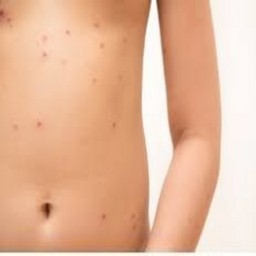

In [96]:
new_image=imread('/content/drive/MyDrive/Skin Disease/Chickenpox/ds1_ChickenPox_25.jpg')
new_image

In [97]:
new_resized=resize(new_image,(150,150,3))
new_resized.shape

(150, 150, 3)

In [98]:
x_train.shape

(1143, 150, 150, 3)

In [99]:
new=new_resized.reshape(1,150,150,3)
new.shape

(1, 150, 150, 3)

In [100]:
result=model.predict(new)
result

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


array([[7.9183235e-07, 2.7089503e-05, 9.9997211e-01, 1.3077790e-19]],
      dtype=float32)

In [101]:
ind=result.argmax()
ind

np.int64(2)

In [102]:
categories[ind]

'Chickenpox'